Loading bureau_balance & bridge tables...
Loaded 500,000 monthly bureau statuses.
Successfully linked across the bridge to 1,996 applicants.


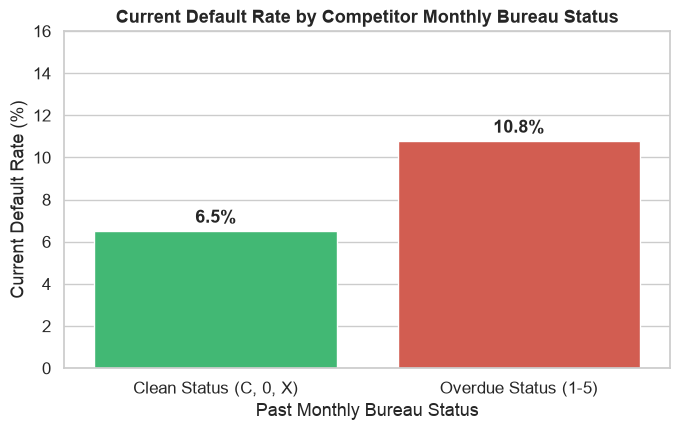

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", font_scale=1.1)

# Smart Path Finder
data_dir = Path("data") if Path("data").exists() else (Path("../data") if Path("../data").exists() else Path("../../data"))

print("Loading bureau_balance & bridge tables...")
# Load sample of bureau_balance
bb = pd.read_csv(data_dir / "bureau_balance.csv", nrows=500000)
bureau_bridge = pd.read_csv(data_dir / "bureau.csv", usecols=["SK_ID_CURR", "SK_ID_BUREAU"])
app = pd.read_csv(data_dir / "application_train.csv", usecols=["SK_ID_CURR", "TARGET"])

print(f"Loaded {len(bb):,} monthly bureau statuses.")


# 1. Map Status Codes to Severity (0 = Clean, 1..5 = Delinquency levels)
status_map = {'C': 0, '0': 0, 'X': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5}
bb["SEVERITY"] = bb["STATUS"].map(status_map).fillna(0).astype(int)


# 2. Hierarchical Aggregation (Snowflake Traversal)
# Step A: Aggregate by Loan ID (SK_ID_BUREAU)
bb_loan_agg = bb.groupby("SK_ID_BUREAU").agg(
    MAX_SEVERITY=("SEVERITY", "max")
).reset_index()

# Step B: Traverse the bridge table to link SK_ID_BUREAU -> SK_ID_CURR
bureau_merged = bureau_bridge.merge(bb_loan_agg, on="SK_ID_BUREAU", how="inner")

# Step C: Aggregate by Applicant (SK_ID_CURR)
bb_client_agg = bureau_merged.groupby("SK_ID_CURR").agg(
    BB_WORST_SEVERITY=("MAX_SEVERITY", "max")
).reset_index()

# Merge with Target
merged_bb = app.merge(bb_client_agg, on="SK_ID_CURR", how="inner")
print(f"Successfully linked across the bridge to {len(merged_bb):,} applicants.")


# 3. Visualize: Does Monthly Status at Other Banks Predict Default?
merged_bb["HAD_STATUS_OVERDUE"] = (merged_bb["BB_WORST_SEVERITY"] >= 1).astype(int)
default_by_bb = merged_bb.groupby("HAD_STATUS_OVERDUE")["TARGET"].mean() * 100
bb_labels = ["Clean Status (C, 0, X)", "Overdue Status (1-5)"]

plt.figure(figsize=(7, 4.5))
ax = sns.barplot(
    x=bb_labels,
    y=default_by_bb.values,
    hue=bb_labels,
    palette=["#2ecc71", "#e74c3c"],
    legend=False
)
plt.title("Current Default Rate by Competitor Monthly Bureau Status", fontsize=13, fontweight="bold")
plt.xlabel("Past Monthly Bureau Status")
plt.ylabel("Current Default Rate (%)")
plt.ylim(0, 16)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height() + 0.4), ha="center", fontweight="bold")

plt.tight_layout()
plt.show()